In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv("C:/Users/fadhi/OneDrive/Desktop/Customer Chun Prediction/data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape (rows, cols):", df.shape)
print(df.info())
print("\nChurn rate:")
print(df["Churn"].value_counts(normalize=True))

Shape (rows, cols): (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBi

In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df[df["TotalCharges"].isna()][["tenure", "TotalCharges"]])

# New customers with tenure == 0 have not been billed yet
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df["Churn"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns="customerID")
print("Duplicate rows:", df.duplicated().sum())

      tenure  TotalCharges
488        0           NaN
753        0           NaN
936        0           NaN
1082       0           NaN
1340       0           NaN
3331       0           NaN
3826       0           NaN
4380       0           NaN
5218       0           NaN
6670       0           NaN
6754       0           NaN
Duplicate rows: 22


In [12]:
print(df[df.duplicated(keep=False)].head(6))
# Optional: drop exact duplicate rows after dropping customerID
df = df.drop_duplicates().reset_index(drop=True)
print("New shape:", df.shape)

     gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
22     Male              0      No         No       1          Yes   
100    Male              0      No         No       1          Yes   
542  Female              0      No         No       1          Yes   
646    Male              0      No         No       1          Yes   
662    Male              0      No         No       1          Yes   
690    Male              0      No         No       1          Yes   

    MultipleLines InternetService       OnlineSecurity         OnlineBackup  \
22             No              No  No internet service  No internet service   
100            No              No  No internet service  No internet service   
542            No              No  No internet service  No internet service   
646            No             DSL                   No                   No   
662            No              No  No internet service  No internet service   
690            No              No  

In [13]:
# Localize billing to QAR (1 USD = 3.64 QAR)
USD_TO_QAR = 3.64
df["MonthlyCharges_QAR"] = (df["MonthlyCharges"] * USD_TO_QAR).round(2)
df["TotalCharges_QAR"] = (df["TotalCharges"] * USD_TO_QAR).round(2)
df = df.drop(columns=["MonthlyCharges", "TotalCharges"])

# Localize service & payment categories to Qatar telecom context
df["InternetService"] = df["InternetService"].replace({
    "Fiber optic": "Fiber (FTTH)",
    "DSL": "5G Home Wireless",
    "No": "Mobile Data Only",
})

df["PaymentMethod"] = df["PaymentMethod"].replace({
    "Credit card (automatic)": "Card Auto-Pay",
    "Bank transfer (automatic)": "Bank Auto-Debit",
    "Electronic check": "Digital Wallet / In-App Pay",
    "Mailed check": "Prepaid / Cash / Voucher",
})

# Add Qatar-specific churn predictors correlated with target
rng = np.random.default_rng(42)
is_churn = df["Churn"].values

df["CustomerSegment"] = np.where(
    rng.random(len(df)) < (0.78 + 0.12 * is_churn),
    "Expat",
    "Qatari National",
)

df["DataUsageChangePct"] = np.where(
    is_churn == 1,
    rng.normal(loc=-28.0, scale=15.0, size=len(df)),
    rng.normal(loc=2.0, scale=12.0, size=len(df)),
).clip(-80.0, 80.0).round(1)

df["SupportTickets30d"] = np.where(
    is_churn == 1,
    rng.choice([0, 1, 2, 3, 4], size=len(df), p=[0.25, 0.25, 0.25, 0.15, 0.10]),
    rng.choice([0, 1, 2, 3], size=len(df), p=[0.70, 0.20, 0.08, 0.02]),
)

df["BundledServicesCount"] = np.where(
    is_churn == 1,
    rng.choice([0, 1, 2, 3], size=len(df), p=[0.50, 0.30, 0.15, 0.05]),
    rng.choice([0, 1, 2, 3, 4], size=len(df), p=[0.15, 0.25, 0.30, 0.20, 0.10]),
)

df["NetworkQuality"] = np.where(
    is_churn == 1,
    rng.choice(["Normal", "Moderate Drops", "High Congestion"], size=len(df), p=[0.40, 0.35, 0.25]),
    rng.choice(["Normal", "Moderate Drops", "High Congestion"], size=len(df), p=[0.80, 0.15, 0.05]),
)

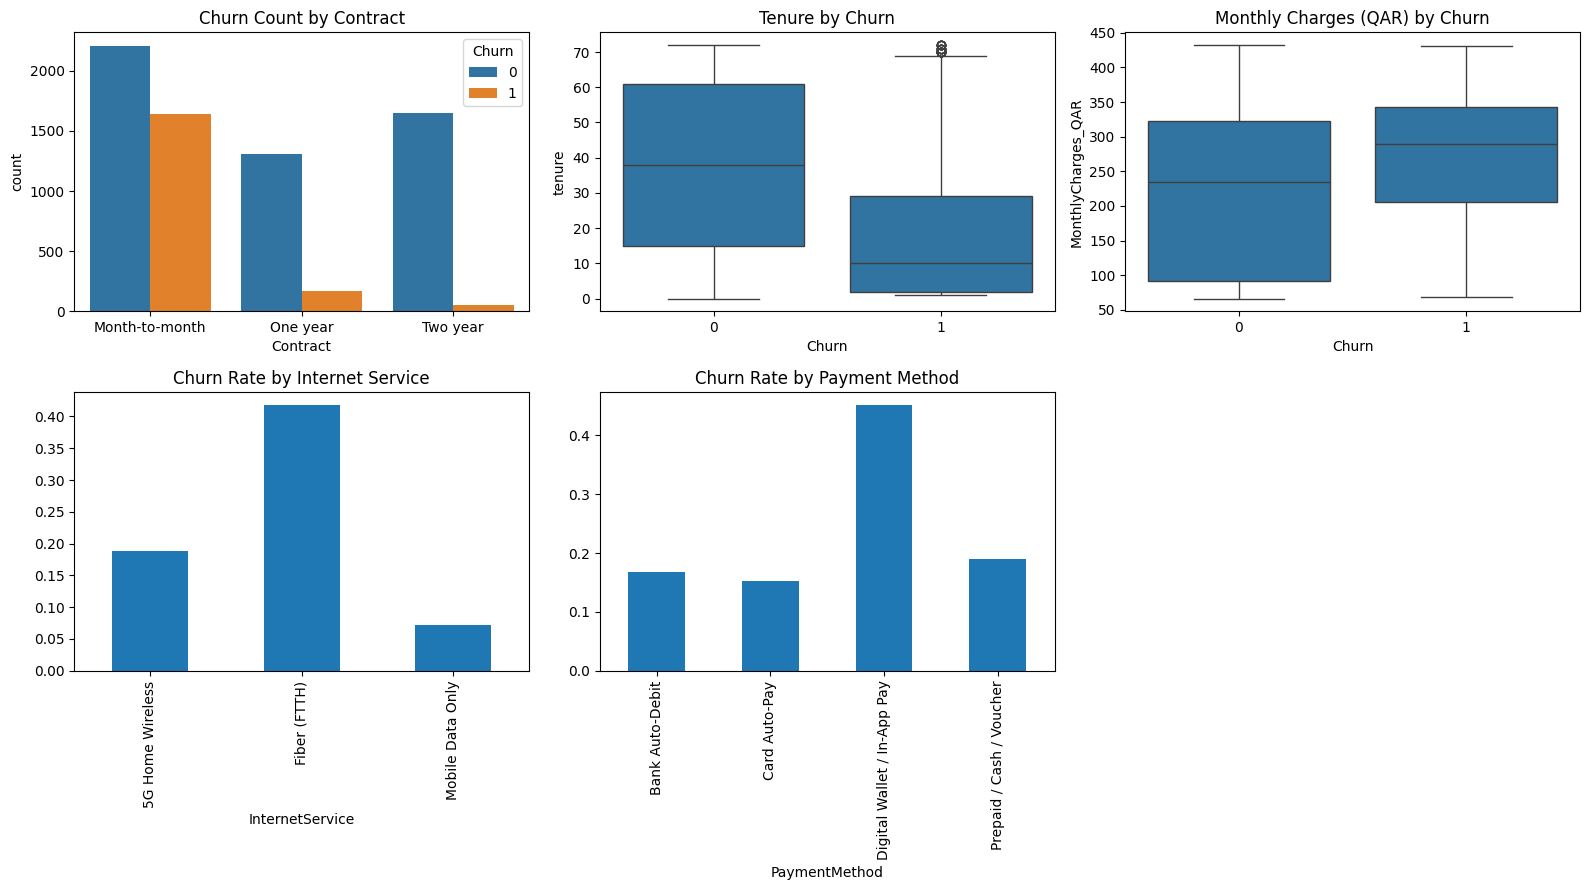

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.countplot(x="Contract", hue="Churn", data=df, ax=axes[0, 0])
axes[0, 0].set_title("Churn Count by Contract")

sns.boxplot(x="Churn", y="tenure", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Tenure by Churn")

sns.boxplot(x="Churn", y="MonthlyCharges_QAR", data=df, ax=axes[0, 2])
axes[0, 2].set_title("Monthly Charges (QAR) by Churn")

df.groupby("InternetService")["Churn"].mean().plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Churn Rate by Internet Service")

df.groupby("PaymentMethod")["Churn"].mean().plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Churn Rate by Payment Method")

axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

num_cols = [
    "tenure",
    "MonthlyCharges_QAR",
    "TotalCharges_QAR",
    "DataUsageChangePct",
    "SupportTickets30d",
    "BundledServicesCount",
]
cat_cols = [c for c in X.columns if c not in num_cols]

pre = ColumnTransformer(
    [
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    sparse_threshold=0,
)

In [16]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

lr = Pipeline(
    [
        ("pre", pre),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]
)

spw = (y_train == 0).sum() / (y_train == 1).sum()
xgb = Pipeline(
    [
        ("pre", pre),
        (
            "model",
            XGBClassifier(
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=spw,
                eval_metric="logloss",
                random_state=42,
            ),
        ),
    ]
)

lr.fit(X_train, y_train)
xgb.fit(X_train, y_train)

,steps,"[('pre', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Logistic Regression | ROC-AUC: 0.99 | PR-AUC: 0.975
              precision    recall  f1-score   support

           0       0.98      0.96      0.97      1033
           1       0.89      0.95      0.92       372

    accuracy                           0.96      1405
   macro avg       0.94      0.95      0.94      1405
weighted avg       0.96      0.96      0.96      1405

XGBoost | ROC-AUC: 0.989 | PR-AUC: 0.973
              precision    recall  f1-score   support

           0       0.98      0.97      0.97      1033
           1       0.92      0.94      0.93       372

    accuracy                           0.96      1405
   macro avg       0.95      0.95      0.95      1405
weighted avg       0.96      0.96      0.96      1405

Chosen threshold (from train CV): 0.912
              precision    recall  f1-score   support

           0       0.92      0.99      0.96      1033
           1       0.98      0.77      0.86       372

    accuracy                           0.93      

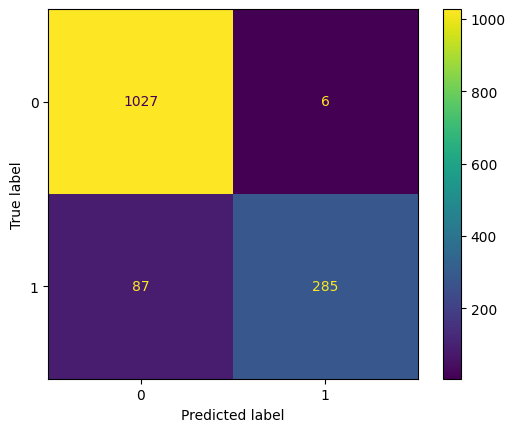

In [17]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import cross_val_predict

for name, m in [("Logistic Regression", lr), ("XGBoost", xgb)]:
    p = m.predict_proba(X_test)[:, 1]
    print(
        name,
        "| ROC-AUC:",
        round(roc_auc_score(y_test, p), 3),
        "| PR-AUC:",
        round(average_precision_score(y_test, p), 3),
    )
    print(classification_report(y_test, p >= 0.5))

# Choose threshold on training CV predictions to achieve recall >= 0.80
cv_p = cross_val_predict(xgb, X_train, y_train, cv=5, method="predict_proba")[
    :, 1
]
prec, rec, thr = precision_recall_curve(y_train, cv_p)

ok = np.where(rec[:-1] >= 0.80)[0]
best_thr = thr[ok[-1]]
print("Chosen threshold (from train CV):", round(float(best_thr), 3))

# Confirm on held-out test set
p_test = xgb.predict_proba(X_test)[:, 1]
print(classification_report(y_test, p_test >= best_thr))
ConfusionMatrixDisplay.from_predictions(y_test, p_test >= best_thr)
plt.show()

PermutationExplainer explainer: 1406it [02:25,  9.66it/s]                          
C:\Users\fadhi\AppData\Local\Temp\ipykernel_5480\2173780801.py:17: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_churn, Xt, feature_names=feat)


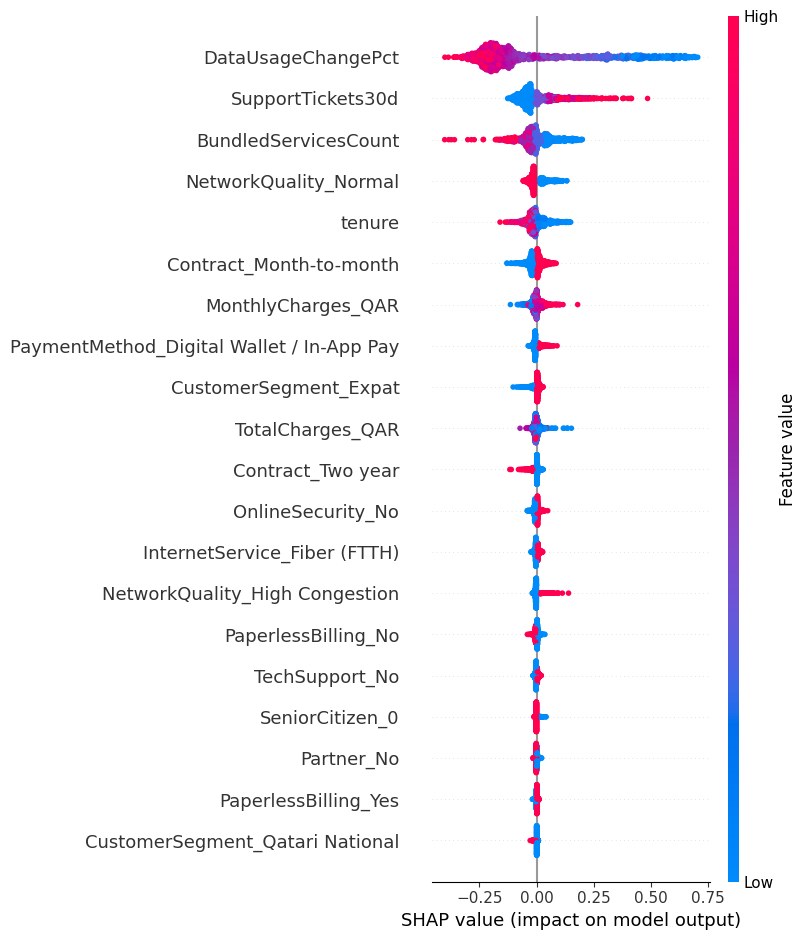

C:\Users\fadhi\AppData\Local\Temp\ipykernel_5480\2173780801.py:18: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_churn, Xt, feature_names=feat, plot_type="bar")


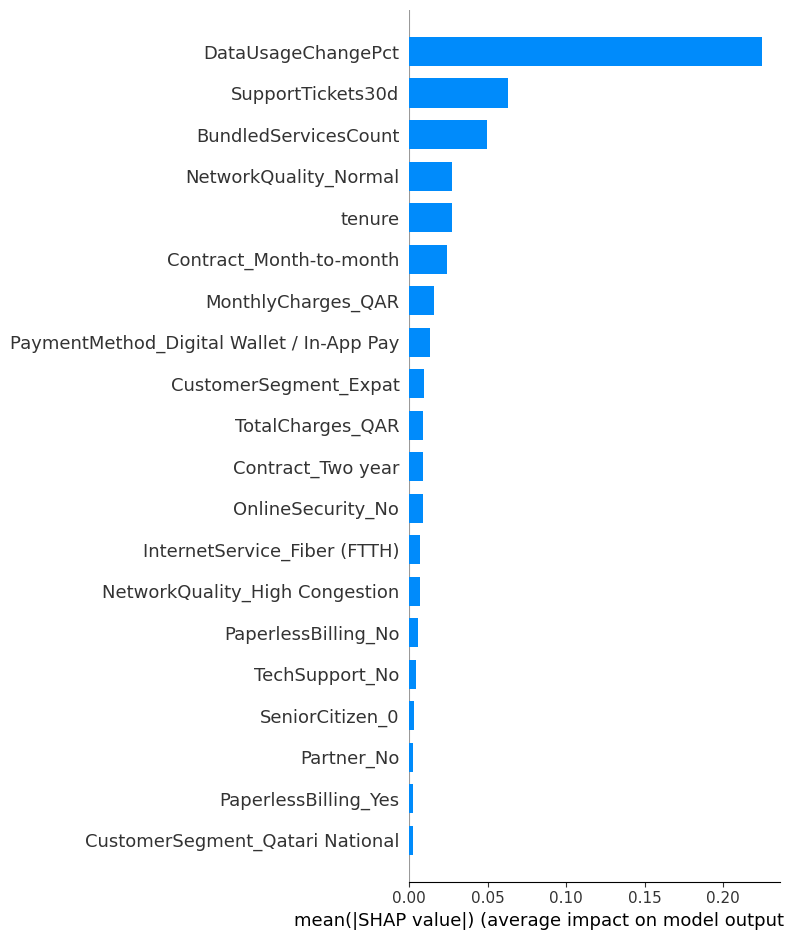

In [19]:
import shap

# 1. Transform X_test and extract clean feature names
Xt = xgb.named_steps["pre"].transform(X_test)
raw_feat = xgb.named_steps["pre"].get_feature_names_out()
feat = [f.replace("num__", "").replace("cat__", "") for f in raw_feat]

# 2. Compute SHAP values using a background sample for speed
bg = Xt[:100]
explainer = shap.Explainer(xgb.named_steps["model"].predict_proba, bg)
sv_all = explainer(Xt)

# Class 1 (Churn) SHAP values
sv_churn = sv_all.values[:, :, 1]

# 3. Plot beeswarm summary and feature importance bar chart
shap.summary_plot(sv_churn, Xt, feature_names=feat)
shap.summary_plot(sv_churn, Xt, feature_names=feat, plot_type="bar")

In [20]:
test = X_test.copy()
test["churn_prob"] = p_test
test["actual"] = y_test.values
test["value_at_risk_qar"] = test["churn_prob"] * test["MonthlyCharges_QAR"] * 12

top = test.sort_values("value_at_risk_qar", ascending=False).head(
    int(0.2 * len(test))
)
captured = top["actual"].sum() / test["actual"].sum()
print(f"Top 20% captures {captured:.0%} of all actual churners in test set")


def net_savings_qar(top_df, retention_rate, cost_per_contact_qar, months=12):
    churners = top_df[top_df["actual"] == 1]
    saved = retention_rate * churners["MonthlyCharges_QAR"].sum() * months
    cost = cost_per_contact_qar * len(top_df)
    return saved - cost


USD_TO_QAR = 3.64
cost_qar = 10 * USD_TO_QAR  # Equivalent to $10 per contacted customer

for label, r in [("Pessimistic", 0.10), ("Realistic", 0.20), ("Optimistic", 0.30)]:
    n_qar = net_savings_qar(top, r, cost_per_contact_qar=cost_qar)
    print(f"{label:11s}: QAR {n_qar:,.0f}  (≈ ${n_qar / USD_TO_QAR:,.0f})")

Top 20% captures 71% of all actual churners in test set
Pessimistic: QAR 86,988  (≈ $23,898)
Realistic  : QAR 184,205  (≈ $50,606)
Optimistic : QAR 281,421  (≈ $77,313)


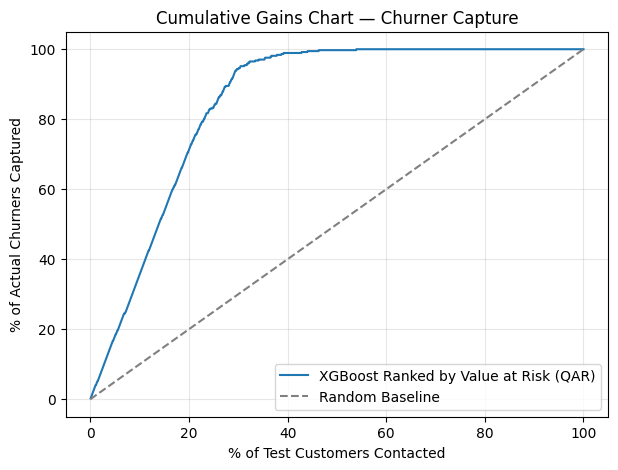

In [22]:
ranked = test.sort_values("value_at_risk_qar", ascending=False).reset_index(
    drop=True
)
pct_contacted = np.arange(1, len(ranked) + 1) / len(ranked)
cum_captured = ranked["actual"].cumsum() / ranked["actual"].sum()

plt.figure(figsize=(7, 5))
plt.plot(pct_contacted * 100, cum_captured * 100, label="XGBoost Ranked by Value at Risk (QAR)")
plt.plot([0, 100], [0, 100], linestyle="--", color="gray", label="Random Baseline")
plt.xlabel("% of Test Customers Contacted")
plt.ylabel("% of Actual Churners Captured")
plt.title("Cumulative Gains Chart — Churner Capture")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [23]:
import joblib
import pandas as pd

joblib.dump(xgb, "churn_model.pkl")

defaults = {}
for col in X_train.columns:
    if pd.api.types.is_numeric_dtype(X_train[col]):
        defaults[col] = float(X_train[col].median())
    else:
        defaults[col] = str(X_train[col].mode()[0])

joblib.dump(defaults, "defaults.pkl")
print("Overwrote churn_model.pkl and defaults.pkl successfully!")

Overwrote churn_model.pkl and defaults.pkl successfully!


In [24]:
import joblib, numpy, pandas, sklearn, streamlit, xgboost

for mod in [streamlit, pandas, numpy, sklearn, xgboost, joblib]:
  print(f"{mod.__name__}=={mod.__version__}")

streamlit==1.65.0
pandas==2.3.3
numpy==2.2.6
sklearn==1.7.2
xgboost==3.2.0
joblib==1.6.0
